In [1]:
import glob
import glob
import numpy as np
import matplotlib
import os
import matplotlib.pyplot as plt
import fspiderman as sp
from kepler_utils import *
from hyperillumination_phasecurve_utils import *
from HItargets_utils import *

looking for fspidermanrc file at ~/.fspidermanrc
no fspidermanrc file detected


In [2]:
FILTER_DIR = "raw SVO"
OUT_DIR    = "Spiderman"
# Data downloaded from http://svo2.cab.inta-csic.es/theory/fps

### Convert SVO ASCII (Angstrom, transmission) -> SPIDERMAN filter file (metres, photon response)

In [3]:
# SPIDERMAN's spiderman.web.get_filter parses with line.strip('\\n').split(' '), so the file must be single-space separated with no header, no comments and no blank lines.
def svo_to_spiderman(svo_file, out_file, thresh=1e-3, pad_frac=0.02, photon_counter=True):
    w_ang, T = np.loadtxt(svo_file, unpack=True)
    w = w_ang * 1e-10  # Angstrom -> metre

    # SVO detector convention: Both JWST/MIRI and Spitzer/IRAC are photon counters (tabulated T(lambda) is electrons per incident photon).
    # SPIDERMAN's get_filter multiplies by hc/lambda internally.
    if not photon_counter: # energy counter -> photon response
        T = T * w / w.max()
    
    # drop the far wings
    keep = T > thresh * T.max() 
    i0, i1 = np.argmax(keep), len(keep) - np.argmax(keep[::-1])
    w, T = w[i0:i1], T[i0:i1]

    # Zero padding outside band
    dw = pad_frac * (w[-1] - w[0])
    w = np.concatenate(([w[0] - dw], w, [w[-1] + dw]))
    T = np.concatenate(([0.0], T, [0.0]))

    np.savetxt(out_file, np.c_[w, T], fmt="%.10e %.10e")
    return w, T

def band_properties(w, T):
    # Pivot wavelength (characteristic wavelength where the band sits) and 50%/1% edges, all in metres.
    lpiv = np.sqrt(np.trapezoid(T * w, w) / np.trapezoid(T / w, w))
    def edges(frac):
        m = T >= frac * T.max()
        return w[m][0], w[m][-1]
    return lpiv, edges(0.5), edges(0.01)

filters = {}
for f in sorted(glob.glob(os.path.join(FILTER_DIR, "*.dat"))):
    name = os.path.splitext(os.path.basename(f))[0]
    out  = os.path.join(OUT_DIR, name + ".spiderman.dat")
    w, T = svo_to_spiderman(f, out)
    lpiv, e50, e01 = band_properties(w, T)
    filters[name] = dict(path=out, w=w, T=T, l1=w[0], l2=w[-1], lpiv=lpiv, e50=e50, e01=e01)

In [4]:
um = 1e6
print(f"{'filter':22s} {'l1 [um]':>9s} {'l2 [um]':>9s} {'pivot':>8s} "
      f"{'50% edges [um]':>20s} {'1% edges [um]':>20s}")
print("-" * 95)
for n, d in filters.items():
    print(f"{n:22s} {d['l1']*um:9.4f} {d['l2']*um:9.4f} {d['lpiv']*um:8.4f} "
          f"{d['e50'][0]*um:9.4f}-{d['e50'][1]*um:<9.4f} "
          f"{d['e01'][0]*um:9.4f}-{d['e01'][1]*um:<9.4f}")

filter                   l1 [um]   l2 [um]    pivot       50% edges [um]        1% edges [um]
-----------------------------------------------------------------------------------------------
JWST_MIRI.F1280W         11.0654   14.5816  12.8101   11.5910-14.1200     11.2540-14.3340  
JWST_MIRI.F1500W         12.7875   17.4925  15.0635   13.5280-16.6370     13.1220-17.1410  
JWST_MIRI.F1800W         15.5725   20.8505  17.9839   16.5210-19.4960     16.0280-20.2850  
Spitzer_IRAC.I2           3.6955    5.1008   4.4959    3.9980-5.0052       3.9194-5.0540   


### Plotting the SVO Throughputs

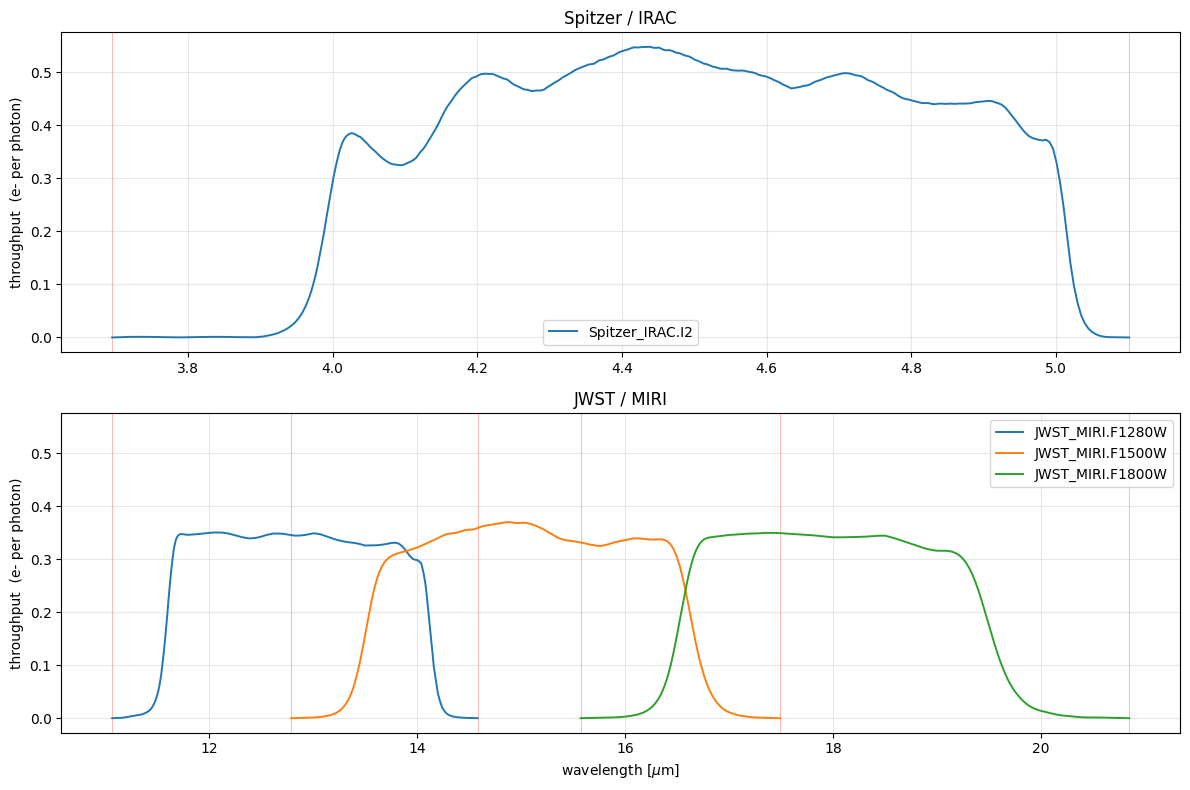

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharey=True)
for n, d in filters.items():
    ax = axes[0] if d["lpiv"] < 8e-6 else axes[1]
    ax.plot(d["w"] * um, d["T"], lw=1.4, label=n)
    ax.axvline(d["l1"] * um, color="red", lw=0.4, zorder=0, alpha=0.5)
    ax.axvline(d["l2"] * um, color="red", lw=0.4, zorder=0, alpha=0.5)
for ax, ttl in zip(axes, ["Spitzer / IRAC", "JWST / MIRI"]):
    ax.set_ylabel("throughput  (e- per photon)")
    ax.set_title(ttl); ax.grid(alpha=.3); ax.legend()
axes[1].set_xlabel(r"wavelength [$\mu$m]")
fig.tight_layout()

### Applied to thermal PhaseCurve model (Spiderman)

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


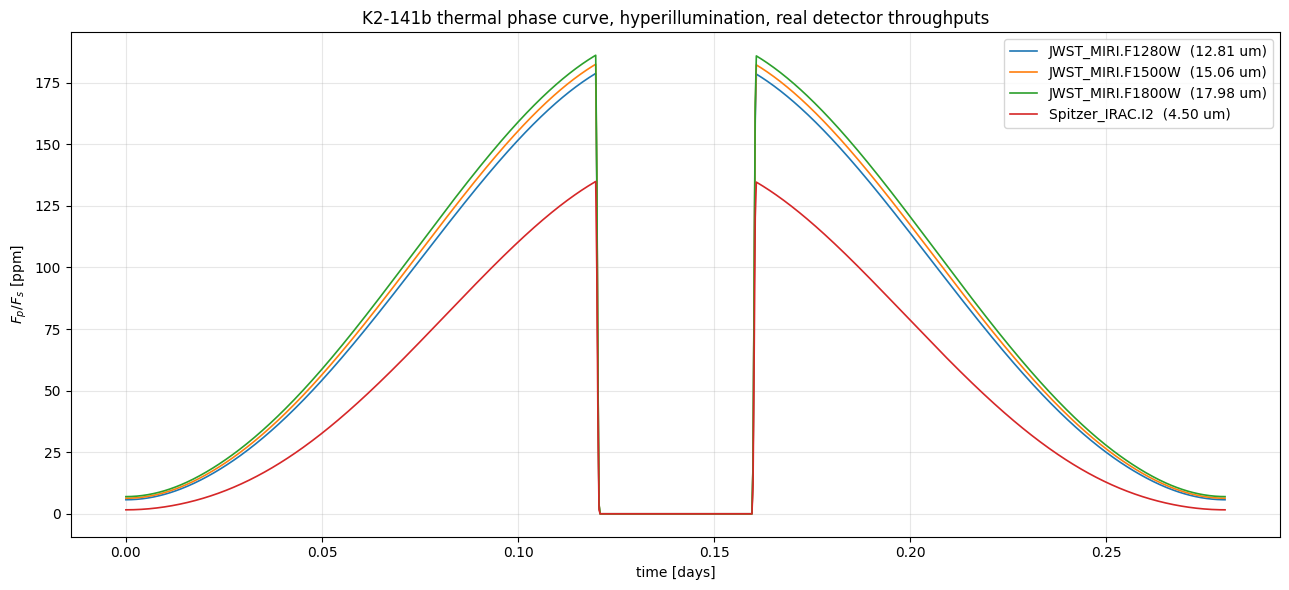

In [7]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
K2_141b = hi_planets_by_name("K2-141 b")
period, incl, ecc, w, rp, r2, a, T_eff, a_AU = K2_141b.args

fp = 142e-6                                 #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from K2-141 data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

Ag = 0.28                                   # Geometric albedo from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
A_B = 3/2*Ag                                # Assuming Lambertian reflectance. PROBABLY UNPHYSICAL!

filter_lambda_ranges = {
    "MIRI/F1280W": [11.0654, 14.5816], # MIRI imaging TSO, F1280W. Below CO₂ band, can check CO₂ atmosphere (combined with F1500W)
    "MIRI/F1500W": [12.7875, 17.4925], # MIRI imaging TSO, F1500W. Used on Trappist (15µm CO₂ band), good for cold nightside
    "MIRI/F1800W": [15.5725, 20.8505], # MIRI imaging TSO, F1800W. MIRI's thermal background climbs steeply past ~15 µm
    "Spitzer/IRAC2": [3.6955, 5.1008] # ~Spitzer IRAC channel 2 (4.5 um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)
}
filter_paths = {
    "MIRI/F1280W": "Spiderman SVO/JWST_MIRI.F1280W.spiderman.dat",
    "MIRI/F1500W": "Spiderman SVO/JWST_MIRI.F1500W.spiderman.dat",
    "MIRI/F1800W": "Spiderman SVO/JWST_MIRI.F1800W.spiderman.dat",
    "Spitzer/IRAC2": "Spiderman SVO/Spitzer_IRAC.I2.spiderman.dat"
}



def thermal_model(l1, l2, insolation_model="hyperillum", filter_path=False, n_lo=200, n_la=100, n_layers=50):
    lo, la, Tg = custom_temperature_grid(K2_141b, n_lo=n_lo, n_la=n_la, insolation_model=insolation_model, A_B=A_B, u_B=u_B)
    T_floor = 100.
    
    LO, LA = np.meshgrid(lo, la, indexing="ij")
    
    p = sp.ModelParams(brightness_model="direct_T", stellar_model="blackbody")
    p.n_layers = n_layers
    p.t0, p.per = 0.0, period
    p.a_abs = a_AU
    p.inc, p.ecc, p.w = incl, ecc, w
    p.rp, p.a = rp, a
    p.p_u1 = p.p_u2 = 0.0
    p.T_s  = T_eff
    p.grid = sp.format_grid(LO, LA, np.maximum(Tg, T_floor).T)
    p.l1, p.l2 = l1, l2
    p.filter = filter_path            # False -> top-hat over [l1, l2]
    return p

# phase curves in every band
t = np.linspace(0, period, 1000)
fig, ax = plt.subplots(figsize=(13, 6))

for n, d in filters.items():
    sg = sp.stellar_grid.gen_grid(d["l1"], d["l2"], logg=4.5, response=d["path"])
    p  = thermal_model(d["l1"], d["l2"], "hyperillum", d["path"])
    ax.plot(t, (fast_lightcurve(p, sg, t) - 1) * 1e6, lw=1.2, label=f"{n}  ({d['lpiv']*um:.2f} um)")

ax.set_xlabel("time [days]"); ax.set_ylabel(r"$F_p/F_s$ [ppm]")
ax.set_title("K2-141b thermal phase curve, hyperillumination, real detector throughputs")
ax.legend()
ax.grid(alpha=.3)
fig.tight_layout()